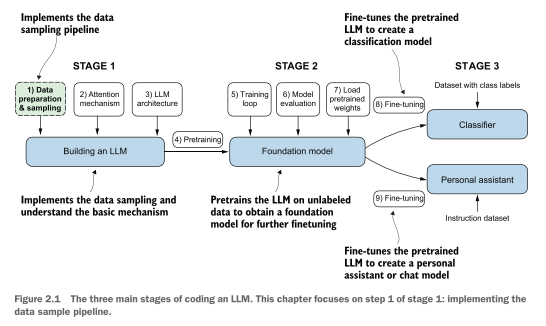

You’ll learn how to prepare input text for training LLMs. This involves splitting text
into individual word and subword tokens, which can then be encoded into vector rep-
resentations for the LLM. You’ll also learn about advanced tokenization schemes like
byte pair encoding, which is utilized in popular LLMs like GPT.

## Understanding word embeddings

The concept of converting data into a vector format is often referred to as embedding.
Using a specific neural network layer or another pretrained neural network model, we
can embed different data types—for example, video, audio, and text.

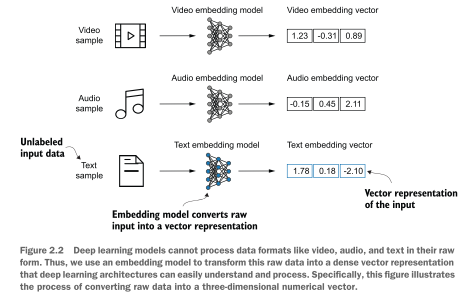

At its core, an embedding is a mapping from discrete objects, such as words, images,
or even entire documents, to points in a continuous vector space—the primary pur-
pose of embeddings is to convert nonnumeric data into a format that neural networks
can process.
While word embeddings are the most common form of text embedding, there are
also embeddings for sentences, paragraphs, or whole documents. Sentence or para-
graph embeddings are popular choices for retrieval-augmented generation. Retrieval-
augmented generation combines generation (like producing text) with retrieval (like
searching an external knowledge base) to pull relevant information when generating
text, which is a technique that is beyond the scope of this book.

Several algorithms and frameworks have been developed to generate word embed-
dings. One of the earlier and most popular examples is the Word2Vec approach.
Word2Vec trained neural network architecture to generate word embeddings by pre-
dicting the context of a word given the target word or vice versa. The main idea
behind Word2Vec is that words that appear in similar contexts tend to have similar
meanings.

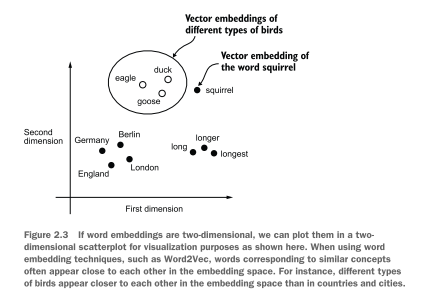

While we can use pretrained models such as Word2Vec to generate embeddings for
machine learning models, LLMs commonly produce their own embeddings that are
part of the input layer and are updated during training. The advantage of optimizing
the embeddings as part of the LLM training instead of using Word2Vec is that the
embeddings are optimized to the specific task and data at hand.

## Tokenizing text

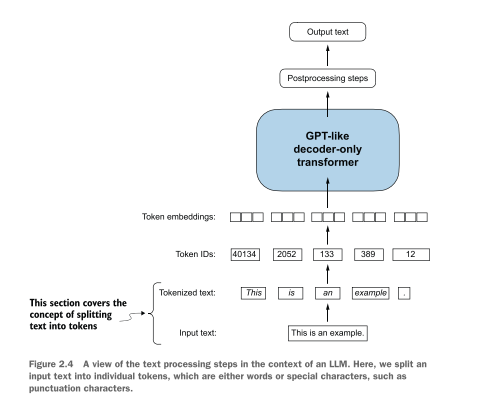

The text we will tokenize for LLM training is “The Verdict,” a short story by Edith
Wharton, which has been released into the public domain and is thus permitted to be
used for LLM training tasks.

In [1]:
with open ("./data/the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

print("Total number of characters: ", len(raw_text))
print(raw_text[:99])

Total number of characters:  20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


> It’s common to process millions of articles and hundreds of thousands
of books—many gigabytes of text—when working with LLMs. However, for
educational purposes, it’s sufficient to work with smaller text samples like a
single book to illustrate the main ideas behind the text processing steps and
to make it possible to run it in a reasonable time on consumer hardware.

In [2]:
import re

In [3]:
text = "Hello, world. This, is a test."
result = re.split(r'(\s)', text)
print(result)

['Hello,', ' ', 'world.', ' ', 'This,', ' ', 'is', ' ', 'a', ' ', 'test.']


This simple tokenization scheme mostly works for separating the example text into
individual words; however, some words are still connected to punctuation characters
that we want to have as separate list entries. We also refrain from making all text lower-
case because capitalization helps LLMs distinguish between proper nouns and com-
mon nouns, understand sentence structure, and learn to generate text with proper
capitalization.

In [4]:
result = re.split(r'([,.]|\s)', text)
print(result)

['Hello', ',', '', ' ', 'world', '.', '', ' ', 'This', ',', '', ' ', 'is', ' ', 'a', ' ', 'test', '.', '']


A small remaining problem is that the list still includes whitespace characters. Option-
ally, we can remove these redundant characters safely as follows:

In [5]:
result = [item for item in result if item.strip()]
print(result)

['Hello', ',', 'world', '.', 'This', ',', 'is', 'a', 'test', '.']


When developing a simple tokenizer, whether we should encode
whitespaces as separate characters or just remove them depends on our appli-
cation and its requirements. Removing whitespaces reduces the memory and
computing requirements. However, keeping whitespaces can be useful if we
train models that are sensitive to the exact structure of the text (for example,
Python code, which is sensitive to indentation and spacing). Here, we remove
whitespaces for simplicity and brevity of the tokenized outputs. Later, we will
switch to a tokenization scheme that includes whitespaces.

The tokenization scheme we devised here works well on the simple sample text. Let’s
modify it a bit further so that it can also handle other types of punctuation

In [6]:
text = "Hello, world. Is this-- a test?"
result = re.split(r'([,.:;?_!"()\']|--|\s)', text)
result = [item.strip() for item in result if item.strip()]
print(result)

['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']


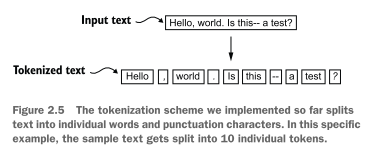

In [7]:
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [item.strip() for item in preprocessed if item.strip()]
print(len(preprocessed))

4690


In [8]:
print(preprocessed[:30])

['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


## Converting tokens into token IDs

Next, let’s convert these tokens from a Python string to an integer representation to
produce the token IDs. This conversion is an intermediate step before converting the
token IDs into embedding vectors.
To map the previously generated tokens into token IDs, we have to build a vocabulary first.
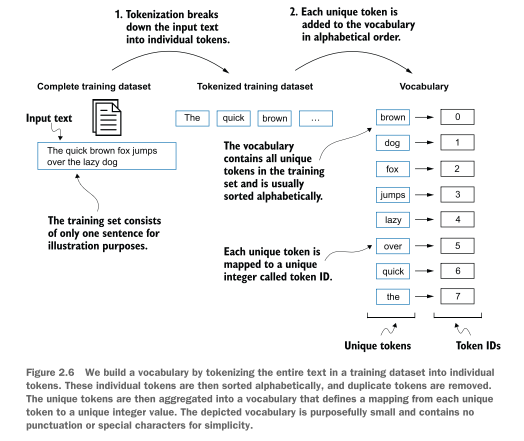

In [9]:
all_words = sorted(set(preprocessed))
vocab_size = len(all_words)
print(vocab_size)

1130


After determining that the vocabulary size is 1,130 via this code, we create the vocabu-
lary and print its first 51 entries for illustration purposes

In [10]:
vocab = {token: integer for integer,token in enumerate(all_words)}

for i, item in enumerate(vocab.items()):
    print(item)
    if i >= 50:
        break


('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)


The dictionary contains individual tokens associated with unique inte-
ger labels. Our next goal is to apply this vocabulary to convert new text into token IDs.

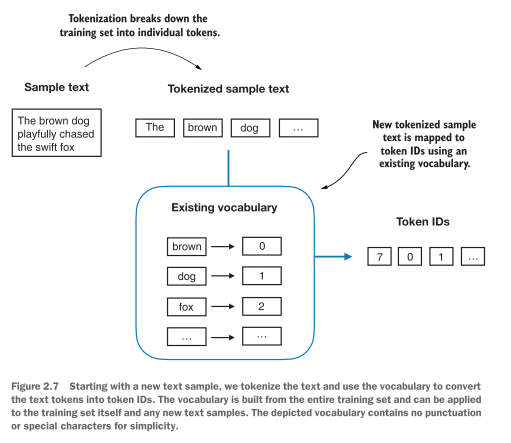

When we want to convert the outputs of an LLM from numbers back into text, we need a
way to turn token IDs into text. For this, we can create an inverse version of the vocabu-
lary that maps token IDs back to the corresponding text tokens.

Let’s implement a complete tokenizer class in Python with an encode method that
splits text into tokens and carries out the string-to-integer mapping to produce token
IDs via the vocabulary. In addition, we’ll implement a decode method that carries out
the reverse integer-to-string mapping to convert the token IDs back into text. The fol-
lowing listing shows the code for this tokenizer implementation.


In [11]:
class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i:s for s,i in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.?_!"()\']|--|\s)', text)
        preprocessed = [item.strip() for item in preprocessed if item.strip()]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text

Using the SimpleTokenizerV1 Python class, we can now instantiate new tokenizer
objects via an existing vocabulary, which we can then use to encode and decode text,



In [12]:
tokenizer = SimpleTokenizerV1(vocab)
text = """"It's the last he painted, you know," Mrs. Gisburn said with pardonable pride."""
ids = tokenizer.encode(text)
print(ids)

[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]


In [13]:
print(tokenizer.decode(ids))

" It' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.


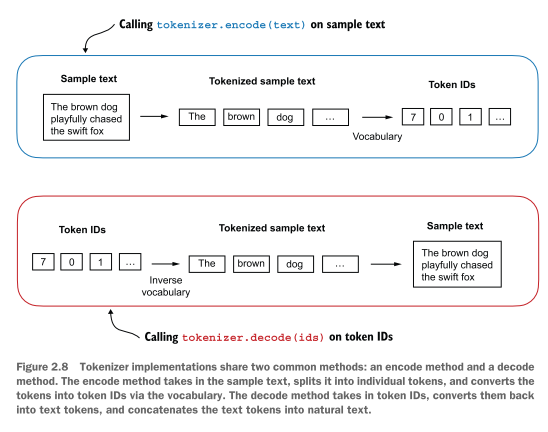

In [14]:
text = "Hello, do you like tea?"
print(tokenizer.encode(text))

KeyError: 'Hello'

The problem is that the word “Hello” was not used in the “The Verdict” short story.
Hence, it is not contained in the vocabulary. This highlights the need to consider
large and diverse training sets to extend the vocabulary when working on LLMs.

## Adding special context tokens

We need to modify the tokenizer to handle unknown words. We also need to address
the usage and addition of special context tokens that can enhance a model’s under-
standing of context or other relevant information in the text. These special tokens
can include markers for unknown words and document boundaries, for example. In
particular, we will modify the vocabulary and tokenizer, SimpleTokenizerV2, to sup-
port two new tokens, <|unk|> and <|endoftext|>

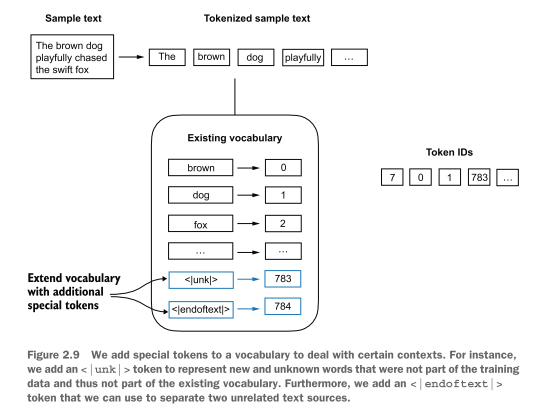
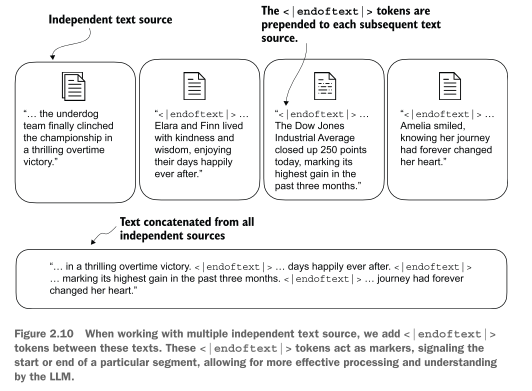

In [15]:
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])
vocab = {token:integer for integer,token in enumerate(all_tokens)}
print(len(vocab.items()))

1132


In [16]:
for i, item in enumerate(list(vocab.items())[-5:]):
    print(item)

('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|>', 1131)


In [17]:
class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = { i:s for s,i in vocab.items()}
        
    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [
        item.strip() for item in preprocessed if item.strip()
        ]
        preprocessed = [item if item in self.str_to_int
            else "<|unk|>" for item in preprocessed]
        ids = [self.str_to_int[s] for s in preprocessed]
        return ids
    
    def decode(self, ids):
        text = " ".join([self.int_to_str[i] for i in ids])
        text = re.sub(r'\s+([,.:;?!"()\'])', r'\1', text)
        return text

In [18]:
text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."
text = " <|endoftext|> ".join((text1, text2))
print(text)

Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.


In [19]:
tokenizer = SimpleTokenizerV2(vocab)
print(tokenizer.encode(text))

[1131, 5, 355, 1126, 628, 975, 10, 1130, 55, 988, 956, 984, 722, 988, 1131, 7]


In [20]:
print(tokenizer.decode(tokenizer.encode(text)))

<|unk|>, do you like tea? <|endoftext|> In the sunlit terraces of the <|unk|>.


Based on comparing this detokenized text with the original input text, we know that
the training dataset, Edith Wharton’s short story “The Verdict,” does not contain the
words “Hello” and “palace.”

Depending on the LLM, some researchers also consider additional special tokens
such as the following:
- [BOS] (beginning of sequence)—This token marks the start of a text. It signifies to the LLM where a piece of content begins.
- [EOS] (end of sequence)—This token is positioned at the end of a text and is especially useful when concatenating multiple unrelated texts, similar to <|endoftext|>. For instance, when combining two different Wikipedia articles or books, the [EOS] token indicates where one ends and the next begins.
- [PAD] (padding)—When training LLMs with batch sizes larger than one, the
batch might contain texts of varying lengths. To ensure all texts have the same
length, the shorter texts are extended or “padded” using the [PAD] token, up to
the length of the longest text in the batch.

Moreover, the tokenizer used for GPT models also doesn’t use an <|unk|> token
for out-of-vocabulary words. Instead, GPT models use a byte pair encoding tokenizer,
which breaks words down into subword units.

## Byte pair encoding

Let’s look at a more sophisticated tokenization scheme based on a concept called byte
pair encoding (BPE). The BPE tokenizer was used to train LLMs such as GPT-2, GPT-3,
and the original model used in ChatGPT. Since implementing BPE can be relatively complicated, we will use an existing
Python open source library called tiktoken



In [21]:
from importlib.metadata import version
import tiktoken
print("tiktoken version: ", version("tiktoken"))

tiktoken version:  0.14.0


In [22]:
tokenizer = tiktoken.get_encoding("gpt2")

In [23]:
text = (
"Hello, do you like tea? <|endoftext|> In the sunlit terraces"
"of someunknownPlace."
)

In [24]:
integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 1659, 617, 34680, 27271, 13]


In [25]:
string = tokenizer.decode(integers)
print(string)

Hello, do you like tea? <|endoftext|> In the sunlit terracesof someunknownPlace.


We can make two noteworthy observations based on the token IDs and decoded text.
First, the <|endoftext|> token is assigned a relatively large token ID, namely, 50256.
In fact, the BPE tokenizer, which was used to train models such as GPT-2, GPT-3, and
the original model used in ChatGPT, has a total vocabulary size of 50,257, with
<|endoftext|> being assigned the largest token ID.
Second, the BPE tokenizer encodes and decodes unknown words, such as
someunknownPlace, correctly. The BPE tokenizer can handle any unknown word. How
does it achieve this without using <|unk|> tokens?
The algorithm underlying BPE breaks down words that aren’t in its predefined
vocabulary into smaller subword units or even individual characters, enabling it to
handle out-of-vocabulary words. So, thanks to the BPE algorithm, if the tokenizer
encounters an unfamiliar word during tokenization, it can represent it as a sequence
of subword tokens or characters

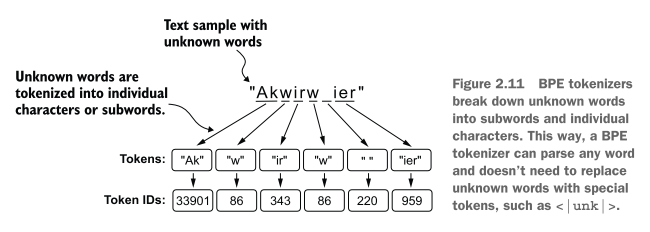

## Data sampling with a sliding window

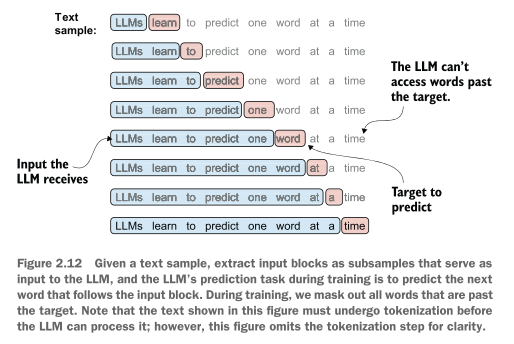

Let’s implement a data loader that fetches the input–target pairs in figure 2.12 from
the training dataset using a sliding window approach. To get started, we will tokenize
the whole “The Verdict” short story using the BPE tokenizer

In [26]:
with open("./data/the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

enc_text = tokenizer.encode(raw_text)
print(len(enc_text))

5145


Executing this code will return 5145, the total number of tokens in the training set,
after applying the BPE tokenizer.
Next, we remove the first 50 tokens from the dataset for demonstration purposes,
as it results in a slightly more interesting text passage in the next steps

In [27]:
enc_sample = enc_text[50:]

One of the easiest and most intuitive ways to create the input–target pairs for the next-
word prediction task is to create two variables, x and y, where x contains the input
tokens and y contains the targets, which are the inputs shifted by 1

In [28]:
context_size = 4
x = enc_sample[:context_size]
y = enc_sample[1:context_size+1]
print(f"x: {x}")
print(f"y:       {y}")

x: [290, 4920, 2241, 287]
y:       [4920, 2241, 287, 257]


By processing the inputs along with the targets, which are the inputs shifted by one
position, we can create the next-word prediction tasks

In [29]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    print(context, "---->", desired)

[290] ----> 4920
[290, 4920] ----> 2241
[290, 4920, 2241] ----> 287
[290, 4920, 2241, 287] ----> 257


Everything left of the arrow (---->) refers to the input an LLM would receive, and
the token ID on the right side of the arrow represents the target token ID that the
LLM is supposed to predict.

In [30]:
for i in range(1, context_size+1):
    context = enc_sample[:i]
    desired = enc_sample[i]
    print(tokenizer.decode(context), "---->", tokenizer.decode([desired]))

 and ---->  established
 and established ---->  himself
 and established himself ---->  in
 and established himself in ---->  a


There’s only one more task before we can turn the tokens into embeddings: imple-
menting an efficient data loader that iterates over the input dataset and returns the inputs and targets as PyTorch tensors, which can be thought of as multidimensional
arrays. In particular, we are interested in returning two tensors: an input tensor con-
taining the text that the LLM sees and a target tensor that includes the targets for the
LLM to predict.

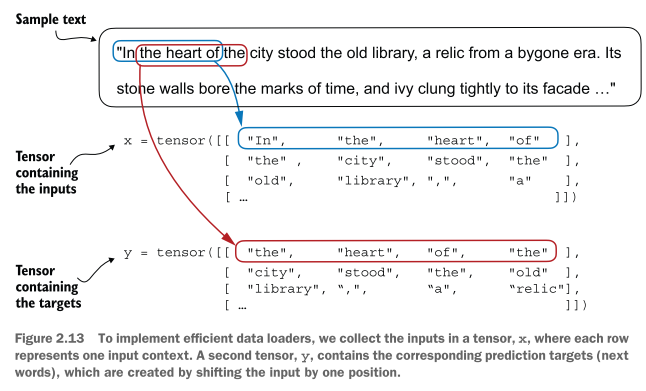

> For the efficient data loader implementation, we will use PyTorch’s
built-in Dataset and DataLoader classes.

In [31]:
import torch
from torch.utils.data import Dataset, DataLoader

In [32]:
class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(txt)

        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1:i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self,idx):
        return self.input_ids[idx], self.target_ids[idx]

The GPTDatasetV1 class is based on the PyTorch Dataset class and defines how indi-
vidual rows are fetched from the dataset, where each row consists of a number of
token IDs (based on a max_length) assigned to an input_chunk tensor. The target_
chunk tensor contains the corresponding targets. I recommend reading on to see what
the data returned from this dataset looks like when we combine the dataset with a
PyTorch DataLoader—this will bring additional intuition and clarity.

The following code uses the GPTDatasetV1 to load the inputs in batches via a PyTorch
DataLoader.

In [33]:
def create_dataloader_v1(txt, batch_size=4, max_length=256, stride=128, shuffle=True, drop_last=True, num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

Let’s test the dataloader with a batch size of 1 for an LLM with a context size of 4 to
develop an intuition of how the GPTDatasetV1 class from listing 2.5 and the create_
dataloader_v1 function from listing 2.6 work together

In [34]:
with open("./data/the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

dataloader = create_dataloader_v1(
    raw_text, batch_size=1, max_length=4, stride=1, shuffle=False
)
data_iter = iter(dataloader)
first_batch = next(data_iter)
print(first_batch)

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]


The first_batch variable contains two tensors: the first tensor stores the input token
IDs, and the second tensor stores the target token IDs. Since the max_length is set to
4, each of the two tensors contains four token IDs. Note that an input size of 4 is quite
small and only chosen for simplicity. It is common to train LLMs with input sizes of at
least 256.

In [35]:
second_batch = next(data_iter)
print(second_batch)

[tensor([[ 367, 2885, 1464, 1807]]), tensor([[2885, 1464, 1807, 3619]])]


If we compare the first and second batches, we can see that the second batch’s token
IDs are shifted by one position (for example, the second ID in the first batch’s input is
367, which is the first ID of the second batch’s input). The stride setting dictates the
number of positions the inputs shift across batches, emulating a sliding window
approach

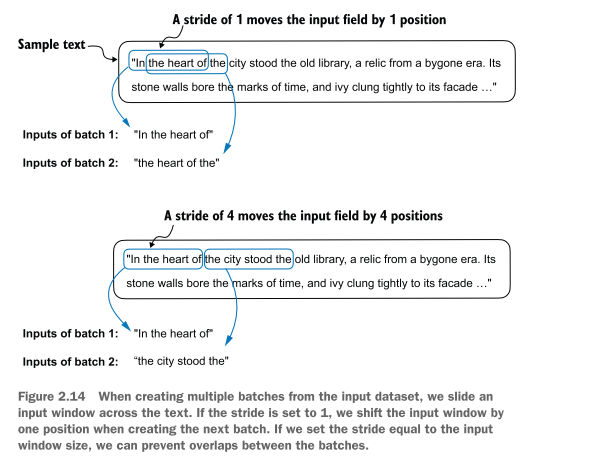

In [36]:
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=4, stride=4,
    shuffle=False
)

data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Inputs:\n", inputs)
print("\nTargets:\n", targets)

Inputs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Targets:
 tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])


## Creating token embeddings

The last step in preparing the input text for LLM training is to convert the token IDs
into embedding vector

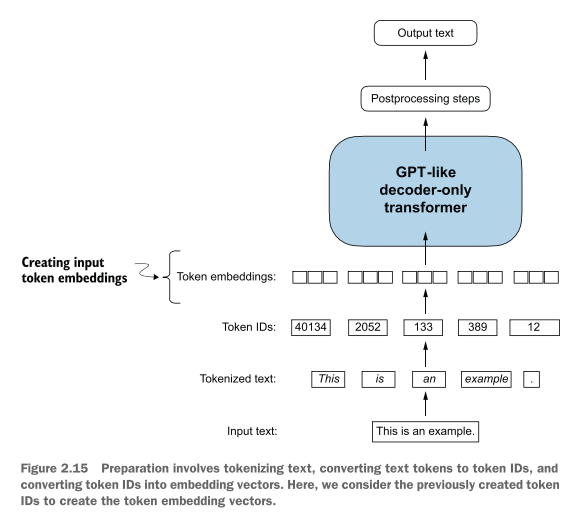

We must initialize these embedding weights with random variables. This initialization serves as the starting
point for the LLM’s learning process.

A continuous vector representation, or embedding, is necessary since GPT-like
LLMs are deep neural networks trained with the backpropagation algorithm.

In [37]:
input_ids = torch.tensor([2,3,5,1])

# small vocabulary of 6 words, and we want to create embedding of size 3
vocab_size = 6
output_dim = 3

In [38]:
torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)
print(embedding_layer.weight)

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)


The weight matrix of the embedding layer contains small, random values. These val-
ues are optimized during LLM training as part of the LLM optimization itself. More-
over, we can see that the weight matrix has six rows and three columns. There is one row
for each of the six possible tokens in the vocabulary, and there is one column for each of
the three embedding dimensions.

In [39]:
print(embedding_layer(torch.tensor([3])))

tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


In [40]:
print(embedding_layer(input_ids))

tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)


Each row in this output matrix is obtained via a lookup operation from the embed-
ding weight matrix, as illustrated in figure 2.16.
Having now created embedding vectors from token IDs, next we’ll add a small
modification to these embedding vectors to encode positional information about a
token within a text.

## Encoding word positions

In principle, token embeddings are a suitable input for an LLM. However, a minor
shortcoming of LLMs is that their self-attention mechanism (see chapter 3) doesn’t
have a notion of position or order for the tokens within a sequence. The way the pre-
viously introduced embedding layer works is that the same token ID always gets
mapped to the same vector representation, regardless of where the token ID is posi-
tioned in the input sequence

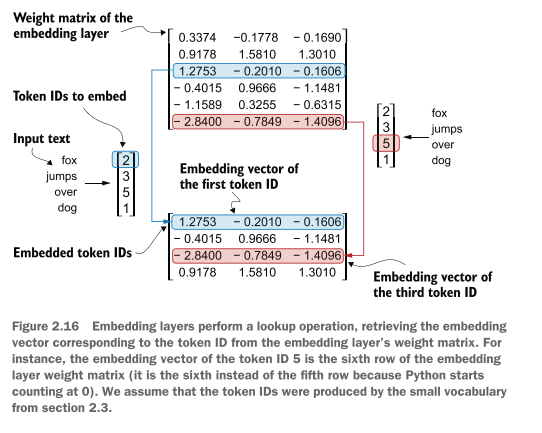

In principle, the deterministic, position-independent embedding of the token ID is
good for reproducibility purposes. However, since the self-attention mechanism of
LLMs itself is also position-agnostic, it is helpful to inject additional position informa-
tion into the LLM.
To achieve this, we can use two broad categories of position-aware embeddings: rela-
tive positional embeddings and absolute positional embeddings. Absolute positional
embeddings are directly associated with specific positions in a sequence. For each posi-
tion in the input sequence, a unique embedding is added to the token’s embedding to
convey its exact location. For instance, the first token will have a specific positional
embedding, the second token another distinct embedding, and so on.
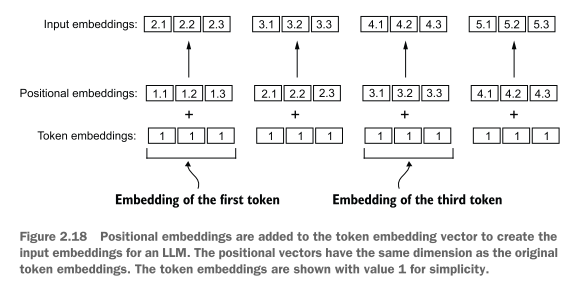

Instead of focusing on the absolute position of a token, the emphasis of relative posi-
tional embeddings is on the relative position or distance between tokens. This means
the model learns the relationships in terms of “how far apart” rather than “at which
exact position.” The advantage here is that the model can generalize better to sequences
of varying lengths, even if it hasn’t seen such lengths during training.
Both types of positional embeddings aim to augment the capacity of LLMs to
understand the order and relationships between tokens, ensuring more accurate and
context-aware predictions. The choice between them often depends on the specific
application and the nature of the data being processed.

We focused on very small embedding sizes for simplicity. Now, let’s con-
sider more realistic and useful embedding sizes and encode the input tokens into a
256-dimensional vector representation, which is smaller than what the original GPT-3
model used (in GPT-3, the embedding size is 12,288 dimensions) but still reasonable
for experimentation. Furthermore, we assume that the token IDs were created by the
BPE tokenizer we implemented earlier, which has a vocabulary size of 50,257

In [41]:
vocab_size = 50257
output_dim = 256
token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

Using the previous token_embedding_layer, if we sample data from the data loader,
we embed each token in each batch into a 256-dimensional vector. If we have a batch
size of 8 with four tokens each, the result will be an 8 × 4 × 256 tensor

In [42]:
max_length = 4
dataloader = create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length,
    stride=max_length, shuffle=False
)
data_iter = iter(dataloader)
inputs, targets = next(data_iter)
print("Token IDs:\n", inputs)
print("\nInputs shape:\n", inputs.shape)

Token IDs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs shape:
 torch.Size([8, 4])


As we can see, the token ID tensor is 8 × 4 dimensional, meaning that the data batch
consists of eight text samples with four tokens each.

In [43]:
token_embeddings = token_embedding_layer(inputs)
print(token_embeddings.shape)

torch.Size([8, 4, 256])


The 8 × 4 × 256–dimensional tensor output shows that each token ID is now embed-
ded as a 256-dimensional vector.

For a GPT model’s absolute embedding approach, we just need to create another
embedding layer that has the same embedding dimension as the token_embedding_
layer

In [44]:
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)
pos_embeddings = pos_embedding_layer(torch.arange(context_length))
print(pos_embeddings.shape)

torch.Size([4, 256])


The input to the pos_embeddings is usually a placeholder vector torch.arange(con-
text_length), which contains a sequence of numbers 0, 1, ..., up to the maximum
input length –1. The context_length is a variable that represents the supported input
size of the LLM.

In [45]:
input_embeddings = token_embeddings + pos_embeddings
print(input_embeddings.shape)

torch.Size([8, 4, 256])


The input_embeddings we created, as summarized in figure 2.19, are the embedded
input examples that can now be processed by the main LLM modules, which we will
begin implementing in the next chapter.
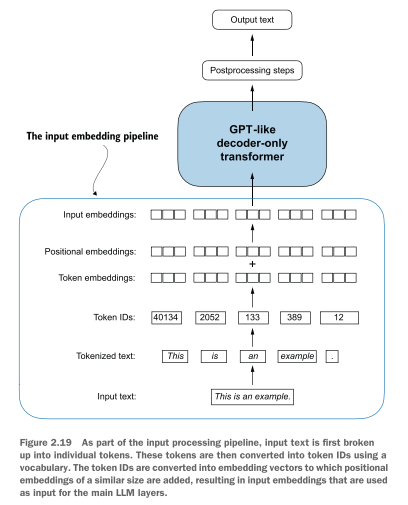